# **Лабораторна робота №3.** Двокритеріальна оптимізація: метод зважених сум та метод ɛ-обмежень

### Крічфалуши Дар'я, 2к. Маг., група МатШІ

**Мета роботи:** Навчитися розв’язувати задачі двокритеріальної оптимізації методом зважених сум і методом ε-обмежень, знаходити компромісні Парето-ефективні точки та будувати фронт Парето засобами Python.

## Завдання (Варіант 4)

1. Записати постановку двокритеріальної задачі та допустиму область $D$.
2. Знайти вручну індивідуальні мінімуми $f_1$ і $f_2$; у кожній з двох точок обчислити обидва критерії.
3. Методом зважених сум: одержати формули $x*(w)$, $f_1(w)$, $f_2(w)$; скласти таблицю для $w = 0; 0,25;
0,5; 0,75; 1$.
4. Методом ε-обмежень: визначити діапазон ε; знайти точки фронту щонайменше для п’яти
значень ε.
5. Реалізувати обидва методи в Python та побудувати графік фронту Парето у просторі $(f_1,f_2)$.
6. Порівняти ручні та чисельні результати, сформулювати висновки.

- $f_1(x_1,x_2)=x_1^2+(x_2-1)^2$
- $f_2(x_1,x_2)=(x_1-2)^2+(x_2-3)^2$
- $D: 0\leq x_1\leq2;\quad 1\leq x_2\leq3$



---



### 1. Постановка двокритеріальної задачі і $D$

**Загальна задача двокритеріальної мінімізації:**


$$
\begin{cases}
  f_1(x),f_2(x)⟶\min\\
  x=(x_1,x_2)\in D
\end{cases}
$$

Для варіанта 4:

- $f_1(x_1,x_2)=x_1^2+(x_2-1)^2$
- $f_2(x_1,x_2)=(x_1-2)^2+(x_2-3)^2$
- $D=\{(x_1,x_2):0\leq x_1\leq2; 1\leq x_2\leq3\}$

**Геометрично** $D$ це замкнений прямокутник, критерії - це квадрати евклідових відстаней до фіксованих точок:

$f_1 = \lVert x - A\rVert^2,\quad A = (0,\,1); \\ f_2 = \lVert x - B\rVert^2,\quad B = (2,\,3);$

Оскільки $A\neq B ⟹$ критерії конфліктуючі. Наближення за одним критерієм віддаляє від іншого:

$$\lVert AB \rVert = \sqrt{(2-0)^2+(3-1)^2} = \sqrt{8} = 2\sqrt{2} \approx 2.8284.$$

Наша задача одночасно оптимізувати два конфліктуючих критерії, тобто: знайти **компромісні рішення - множину Парето**.

#### 1.1. Парето-оптимальна точка

**Означення 1.** Точка $x^*\in D$ є **Парето-оптимальною**(ефективною), якщо неіснує $x\in D:$ такої, що

$\forall i\in ℕ: f_i(x)\leq f_i(x^*)\quad$ і $\quad f_j(x)< f_j(x^*)$ хоча б для одного $j$

Множина таких точок у просторі змінних - **множина Парето**, а її образ у просторі критеріїв $(f_1,f_2)$ - **фронт Парето**.

#### 1.2. Метод зважених сум (Weighted Sum Method)

Об'єднує два критерії в одну скалярну цільову функцію за допомогою **вагових коефіцієнтів** $w_k, k\inℕ_0:$

$$
𝑱_w(x)=w\cdot f_1(x) + (1-w)\cdot f_2(x),\quad 0\leq w\leq 1,
$$

$$
w_k=\dfrac{k}{N},\quad k=0,1,\dots,N.
$$

Для кожного $w$ розв'язується одна скалярна задача мінімізації. Умова стаціонарності:

$$
\nabla 𝑱_w(x)=0
$$

#### 1.3. Метод ɛ-обмежень

Цей підхід залишає один критерій як **головну цільову функцію**, а другий переводить у категорію **жорстких обмежень**:

$$
\begin{cases}
  f_1(x) ⟶\min\\
  f_2(x)\leq ɛ\\
  x\in D
\end{cases}
$$

де ɛ - сітка значень:

$$
ɛ_k = f_{2,\min}+k\cdot\dfrac{f_{2,\max}-f_{2,\min}}{N},\quad k=0,1,\dots,N.
$$

### 2. Індивідуальні мінімуми $f_1$, $f_2$ і обчислення

#### 2.1. Мінімум $f_1$

1. Обчислимо частинні похідні по $x_1,x_2$ і прирівняємо результати до $0$.

$
\begin{cases}
  \dfrac{∂f_1}{\partial x_1}=0\\
  \dfrac{∂f_1}{\partial x_2}=0
\end{cases}
⟶
$
$
\begin{cases}
  2x_1=0\\
  2x_2-2=0
\end{cases}
⟶
$
$
\begin{cases}
  x_1=0\\
  x_2=1
\end{cases}
⟹
$

Стаціонарна точка $f_1:(0,1)$

2. Перевіряємо чи є стаціонарна точка екстремумом за 2 похідною.

$
\begin{cases}
  \dfrac{∂^2f_1}{\partial x_1^2}=2\\
  \dfrac{∂^2f_1}{\partial x_2^2}=2\\
  \dfrac{\partial^2f_1}{\partial x_1x_2}=0
\end{cases}
⟶\text{складаємо матрицю Гессе}
$
$H_{f_1} = \begin{pmatrix} 2 & 0 \\ 0 & 2\end{pmatrix}$

$Δ_1=2>0,\quad Δ_2=2\cdot2-0=4>0⟹$ Матриця є додатно визначеною, а отже, стаціонарна точка $(0,1)$ є **точкою глобального мінімума**.

**Значення функцій (критеріїв)** в точці мінімума:

$f_1(0,1)= 0^2+(1-1)^2=0$

$f_2(0,1)=(0-2)^2+(1-3)^2=8$



#### 2.2. Мінімум $f_2$

1. Обчислимо частинні похідні по $x_1,x_2$ і прирівняємо результати до $0$.

$
\begin{cases}
  \dfrac{∂f_2}{\partial x_1}=0\\
  \dfrac{∂f_2}{\partial x_2}=0
\end{cases}
⟶
$
$
\begin{cases}
  2x_1-4=2(x_1-2)=0\\
  2x_2-6=2(x_2-3)=0
\end{cases}
⟶
$
$
\begin{cases}
  x_1=2\\
  x_2=3
\end{cases}
⟹
$

Стаціонарна точка $f_2:(2,3)$

2. Перевіряємо чи є стаціонарна точка екстремумом за 2 похідною.

$
\begin{cases}
  \dfrac{∂^2f_2}{\partial x_1^2}=2\\
  \dfrac{∂^2f_2}{\partial x_2^2}=2\\
  \dfrac{\partial^2f_2}{\partial x_1x_2}=0
\end{cases}
⟶\text{складаємо матрицю Гессе}
$
$H_{f_1} = \begin{pmatrix} 2 & 0 \\ 0 & 2\end{pmatrix}$

$Δ_1=2>0,\quad Δ_2=2\cdot2-0=4>0⟹$ Матриця є додатно визначеною, а отже, стаціонарна точка $(2,3)$ є **точкою глобального мінімума**.

**Значення функцій (критеріїв)** в точці мінімума

$f_1(2,3)= 2^2+(3-1)^2=8$

$f_2(2,3)=(2-2)^2+(3-3)^2=0$

**! Зауваження.** У загальному випадку обов'язково треба перевірити окремо межі заданої області. У нашому випадку так вийшло, що точки мінімума і є межами.

### 3. Метод зважених сум

Методом зважених сум: одержати формули $x^*(w)$, $f_1(w)$, $f_2(w)$; скласти таблицю для $w = 0; 0,25;
0,5; 0,75; 1$.

За означенням:

$
𝑱_w(x)=w\cdot f_1(x) + (1-w)\cdot f_2(x),\quad 0\leq w\leq 1,
$

1) Підставимо наші критерії:

$
𝑱_w(x)=w\cdot (x_1^2 + (x_2-1)^2) + (1-w)\cdot ((x_1-2)^2+(x_2-3)^2),\quad 0\leq w\leq 1,
$

2) Умови стаціонарності:

$
\begin{cases}
  \dfrac{\partial𝑱_w}{\partial x_1}=0\\
  \dfrac{\partial𝑱_w}{\partial x_2}=0
\end{cases}
⟹
$
$
\begin{cases}
  2wx_1 + 2(1-w)(x_1-2)=0\\
  2w(x_2-1) + 2(1-w)(x_2-3)=0
\end{cases}
⟹
$

$⟹
\begin{cases}
  wx_1 + (1-w)x_1 - 2(1-w)=0\\
  wx_2 - w + (1-w)x_2 - 3(1-w)=0
\end{cases}
⟹
$
$
\begin{cases}
  x_1 - 2 + 2w=0\\
  x_2 - w - 3(1-w)=0
\end{cases}
⟹
$

$$
\boxed{
x_1^*(w)=2-2w}
\quad
\boxed{
x_2^*(w)=3-2w
}
$$

3) Перевірка КУ:

**Чи** $x_1^*\in[0,2],x_2^*\in[1,3]$ при $w\in[0,1]$?

$$
x_1^*(0)=2-0=2,\quad
x_1^*(1)=2-2=0
$$

$$
x_2^*(0)=3-0=3,\quad
x_2^*(1)=3-2=1
$$

**Так!**

4) $x^*(x_1^*(w),x_2^*(w))=(2-2w, 3-2w)=w\cdot(0,1) + (1-w)\cdot(2,3)$

З чого можна зробити висновок, що множина **Парето вироджується у прямолінійний розв'язок** $AB$, тобто

$$
x_2=x_1+1,\quad x_1\in[0,2]
$$

5) $f_1(w)=(2-2w)^2+(3-2w-1)^2=(2-2w)^2+(2-2w)^2=$

$=2(2-2w)^2=2(4-8w+4w^2)=8(1-2w+w^2)=\boxed{8(1-w)^2.}$


6) $f_2(w)=(2-2w-2)^2+(3-2w-3)^2=\boxed{8w^2.}$

7) Рівняння **фронту Парето** в аналітичному вигляді:

$
\begin{cases}
  \sqrt{f_1} = 2\sqrt2\cdot|1-w| \\
  \sqrt{f_2} = 2\sqrt2\cdot|w|
\end{cases}
⟹
$
$\boxed{\sqrt{f_1} + \sqrt{f_2}=2\sqrt2≈2.8284}$

8) Таблиця розрахунків для $w=0; 0.25; 0.5; 0.75; 1$:


| $w$ | $x_1^*$| $x_2^*$| $f_1$ |$f_2$ |
|:----:|:---:|:---:|:-----:|:-----:|
| 0    | 2.0 | 3.0 | 8.000 | 0.000 |
| 0.25 | 1.5 | 2.5 | 4.500 | 0.500 |
| 0.5  | 1.0 | 2.0 | 2.000 | 2.000 |
| 0.75 | 0.5 | 1.5 | 0.500 | 4.500 |
| 1    | 0.0 | 1.0 | 0.000 | 8.000 |

### 4. Метод ɛ-обмежень

Методом ε-обмежень: визначити діапазон ε; знайти точки фронту щонайменше для п’яти значень ε

За означенням:

$$
\begin{cases}
  f_1(x) ⟶\min\\
  f_2(x)\leq ɛ\\
  x\in D
\end{cases}
$$

де ɛ - сітка значень:

$$
ɛ_k = f_{2,\min}+k\cdot\dfrac{f_{2,\max}-f_{2,\min}}{N},\quad k=0,1,\dots,N.
$$

Так як **ɛ** залежить від $f_2$ і на точки мінімумів визначені на краях діапазонів критеріїв $f_1$ і $f_2$, то діапазон цього епсілона ми визначаємо не більший і не менший за діапазон $f_2$, тому якщо $N=4$:

$$
ɛ_k=k\cdot\dfrac{8-0}{4}=2k,\quad k=0,\dots4.
$$

Тоді маємо $ɛ=\{0,2,4,6,8\}.$

#### 4.1. Метод Лагранжа

Методом Лагранжа знайдемо розв'язок оптимізаційної задачі з ɛ-обмеженнями.

1) Визначаємо функцію Лагранжа:

$$
L(x,\mu)=f_1(x)+\mu(f_2(x)-ɛ),\quad\mu\geq0
$$

2) Умови стаціонарності:

$
\begin{cases}
  \dfrac{\partial L}{\partial x_1}=2x_1+2\mu(x_1-2)=0\\
  \dfrac{\partial L}{\partial x_2}=2(x_2-1)+2\mu(x_2-3)=0
\end{cases}
⟹
$
$
\begin{cases}
  x_1(1+\mu)=2\mu\\
  x_2(1+\mu)=1+3\mu
\end{cases}
⟹
$

$$
x_1=\dfrac{2\mu}{1+\mu},\quad x_2=\dfrac{1+3\mu}{1+\mu}
$$

3) Підставляємо отримані $x_1,x_2$ у $f_2$:

$$
f_2(x_1,x_2)=\left(\dfrac{2\mu}{1+\mu}-2\right)^2 + \left( \dfrac{1+3\mu}{1+\mu}-3\right)^2=
$$


$
=\left(\dfrac{2\mu-2-2\mu}{1+\mu} \right)^2 + \left(\dfrac{1+3\mu-3-3\mu}{1+\mu} \right)^2=\dfrac{4}{(1+\mu)^2} + \dfrac{4}{(1+\mu)^2}=\dfrac{8}{(1+\mu)^2}.
$

$⟹ \dfrac{8}{(1+\mu)^2}=ɛ⟹(1+\mu)^2=\dfrac{8}{ɛ}⟹ 1+\mu=\pm\sqrt{\dfrac{8}{ɛ}}⟹\boxed{\mu=\dfrac{2\sqrt2}{\sqrtɛ}-1}$

4. Підставляємо назад у $x_1$:

$
x_1(\mu)=\dfrac{2\mu}{1+\mu}=2\left(1-\dfrac{1}{1+\mu} \right)⟹ 2-\sqrt{\dfrac{ɛ}{2}}.
$

Позначимо $t(ɛ)=2-\sqrt{\dfrac{ɛ}{2}}$, тоді:

$$
\boxed{x^*(ɛ)=(t,1+t),\quad f_1=2t^2,\quad f_2=ɛ}
$$

При $ɛ\in[0,8].$



---



### 6. Реалізація на Python та побудова графіку Парето

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.facecolor": "white"})

A = np.array([0.0, 1.0])   # центр f1
B = np.array([2.0, 3.0])   # центр f2
D = [(0.0, 2.0), (1.0, 3.0)]

def f1(x):
  x = np.asarray(x, dtype=float)
  return x[0]**2 + (x[1] - 1.0)**2

def f2(x):
  x = np.asarray(x, dtype=float)
  return (x[0] - 2.0)**2 + (x[1] - 3.0)**2

def F(x):
  # вектор критеріїв
  return np.array([f1(x), f2(x)])

print("f1(x) = x1^2 + (x2-1)^2        -> центр a = ", A)
print("f2(x) = (x1-2)^2 + (x2-3)^2    -> центр b = ", B)
print("D: 0 <= x1 <= 2,  1 <= x2 <= 3")
print("||ab|| = ", np.linalg.norm(B - A), " = 2*sqrt(2) = ", 2*np.sqrt(2))

f1(x) = x1^2 + (x2-1)^2        -> центр a =  [0. 1.]
f2(x) = (x1-2)^2 + (x2-3)^2    -> центр b =  [2. 3.]
D: 0 <= x1 <= 2,  1 <= x2 <= 3
||ab|| =  2.8284271247461903  = 2*sqrt(2) =  2.8284271247461903


In [17]:
# Завдання 2: Індивідуальні мінімуми (чисельно)
x0 = np.array([1.0, 2.0])

r1 = minimize(f1, x0, bounds=D, tol=1e-14)
r2 = minimize(f2, x0, bounds=D, tol=1e-14)

print(f"{'':16s}{'x*':>22s}{'f1':>12s}{'f2':>12s}")
print(f"{'мінімум f1':16s}{str(np.round(r1.x, 6)):>22s}{f1(r1.x):12.6f}{f2(r1.x):12.6f}")
print(f"{'мінімум f2':16s}{str(np.round(r2.x, 6)):>22s}{f1(r2.x):12.6f}{f2(r2.x):12.6f}")

f2_min, f2_max = f2(r2.x), f2(r1.x)
f1_min, f1_max = f1(r1.x), f1(r2.x)
print(f'\nідеальна точка  f* = ({f1_min:.4f}, {f2_min:.4f})')
print(f'надир-точка   f_nad = ({f1_max:.4f}, {f2_max:.4f})')
print(f'діапазон eps        = [{f2_min:.4f}, {f2_max:.4f}]')

# звірка з ручними викладками
assert np.allclose(r1.x, [0, 1], atol=1e-6) and np.allclose(r2.x, [2, 3], atol=1e-6)
print('\n[OK] збігається з ручними викладками: (0,1) та (2,3)')

                                    x*          f1          f2
мінімум f1                     [0. 1.]    0.000000    8.000000
мінімум f2                     [2. 3.]    8.000000    0.000000

ідеальна точка  f* = (0.0000, 0.0000)
надир-точка   f_nad = (8.0000, 8.0000)
діапазон eps        = [0.0000, 8.0000]

[OK] збігається з ручними викладками: (0,1) та (2,3)


In [18]:
# Завдання 3: Метод зважених сум

def weighted_sum(w, x_start=np.array([1.0, 2.0])):
  # Мінімізує J_w = w*f1 + (1-w)*f2 на D. Повертає x*
  J = lambda x: w * f1(x) + (1.0 - w) * f2(x)
  res = minimize(J, x_start, bounds=D, tol=1e-14)
  return res.x

# аналітичні формули з п. 4
x_analytic_ws = lambda w: np.array([2 - 2*w, 3 - 2*w])
f1_analytic_ws = lambda w: 8 * (1 - w)**2
f2_analytic_ws = lambda w: 8 * w**2

W_TABLE = [0.0, 0.25, 0.5, 0.75, 1.0]

print('Метод зважених сум')
print(f"{'w':>6}{'x1*':>10}{'x2*':>10}{'f1':>12}{'f2':>12}"
      f"{'f1 ручн.':>12}{'f2 ручн.':>12}{'sqrt f1+sqrt f2':>18}{'похибка':>11}")
print('-' * 103)
ws_rows = []
for w in W_TABLE:
  x = weighted_sum(w)
  a, b = f1(x), f2(x)
  err = max(abs(a - f1_analytic_ws(w)), abs(b - f2_analytic_ws(w)),
            np.abs(x - x_analytic_ws(w)).max())
  ws_rows.append((w, x[0], x[1], a, b))
  print(f'{w:6.2f}{x[0]:10.4f}{x[1]:10.4f}{a:12.6f}{b:12.6f}'
        f'{f1_analytic_ws(w):12.6f}{f2_analytic_ws(w):12.6f}'
        f'{np.sqrt(a)+np.sqrt(b):18.6f}{err:11.2e}')

print('\n2*sqrt(2) =', 2*np.sqrt(2), ' <- усі точки лежать на фронті sqrt(f1)+sqrt(f2)=2sqrt2')

Метод зважених сум
     w       x1*       x2*          f1          f2    f1 ручн.    f2 ручн.   sqrt f1+sqrt f2    похибка
-------------------------------------------------------------------------------------------------------
  0.00    2.0000    3.0000    8.000000    0.000000    8.000000    0.000000          2.828427   0.00e+00
  0.25    1.5000    2.5000    4.500000    0.500000    4.500000    0.500000          2.828427   6.64e-08
  0.50    1.0000    2.0000    2.000000    2.000000    2.000000    2.000000          2.828427   0.00e+00
  0.75    0.5000    1.5000    0.500000    4.500000    0.500000    4.500000          2.828427   2.03e-08
  1.00    0.0000    1.0000    0.000000    8.000000    0.000000    8.000000          2.828427   0.00e+00

2*sqrt(2) = 2.8284271247461903  <- усі точки лежать на фронті sqrt(f1)+sqrt(f2)=2sqrt2


In [19]:
# Завдання 4: Mетод ε-обмежень

def eps_constraint(eps, n_starts=4):
  #min f1 за умови f2 <= eps, x in D. Мультистарт проти локальних зупинок SLSQP."""
  cons = [{'type': 'ineq', 'fun': lambda x, e=eps: e - f2(x)}]   # e - f2(x) >= 0
  starts = [np.array([0.1, 1.1]), np.array([1.0, 2.0]),
            np.array([1.9, 2.9]), np.array([0.5, 2.5])][:n_starts]
  best = None
  for s in starts:
    res = minimize(f1, s, bounds=D, constraints=cons, method='SLSQP',
                   options={'ftol': 1e-14, 'maxiter': 500})
    if res.success and f2(res.x) <= eps + 1e-7:
      if best is None or f1(res.x) < f1(best):
        best = res.x
  return best

# аналітичні формули з п. 5
t_analytic = lambda e: 2 - np.sqrt(e / 2)
x_analytic_eps = lambda e: np.array([t_analytic(e), 1 + t_analytic(e)])
f1_analytic_eps = lambda e: 2 * t_analytic(e)**2

N = 4
EPS_TABLE = [f2_min + k * (f2_max - f2_min) / N for k in range(N + 1)]

print('Метод ε-обмежень        eps_k =', np.round(EPS_TABLE, 4))
print(f"\n{'eps':>6}{'x1*':>10}{'x2*':>10}{'f1':>12}{'f2':>12}"
      f"{'f1 ручн.':>12}{'mu':>10}{'екв. w':>10}{'похибка':>11}")
print('-' * 93)
eps_rows = []
for e in EPS_TABLE:
  x = eps_constraint(e)
  a, b = f1(x), f2(x)
  mu = (2*np.sqrt(2)/np.sqrt(e) - 1) if e > 0 else np.inf
  w_eq = np.sqrt(e / 8)
  err = max(abs(a - f1_analytic_eps(e)), np.abs(x - x_analytic_eps(e)).max())
  eps_rows.append((e, x[0], x[1], a, b))
  print(f'{e:6.2f}{x[0]:10.4f}{x[1]:10.4f}{a:12.6f}{b:12.6f}'
  f'{f1_analytic_eps(e):12.6f}{mu:10.4f}{w_eq:10.4f}{err:11.2e}')

Метод ε-обмежень        eps_k = [0. 2. 4. 6. 8.]

   eps       x1*       x2*          f1          f2    f1 ручн.        mu    екв. w    похибка
---------------------------------------------------------------------------------------------
  0.00    2.0000    3.0000    8.000000    0.000000    8.000000       inf    0.0000   5.22e-08
  2.00    1.0000    2.0000    2.000000    2.000000    2.000000    1.0000    0.5000   1.72e-09
  4.00    0.5858    1.5858    0.686292    4.000000    0.686292    0.4142    0.7071   1.17e-09
  6.00    0.2679    1.2679    0.143594    6.000000    0.143594    0.1547    0.8660   1.09e-09
  8.00    0.0000    1.0000    0.000000    8.000000    0.000000    0.0000    1.0000   0.00e+00


In [20]:
# Прямий перебір + фільтр за домінуванням (для графіків)
# Незалежна перевірка, що знайдені точки справді Парето-оптимальні.

def pareto_mask(Fvals):
  # True для недомінованих рядків матриці критеріїв
  n = len(Fvals)
  mask = np.ones(n, dtype=bool)
  for i in range(n):
      if not mask[i]:
          continue
      dominated = np.all(Fvals <= Fvals[i], axis=1) & np.any(Fvals < Fvals[i], axis=1)
      if dominated.any():
          mask[i] = False
  return mask

g1 = np.linspace(0, 2, 121)
g2 = np.linspace(1, 3, 121)
G1, G2 = np.meshgrid(g1, g2)
GRID = np.column_stack([G1.ravel(), G2.ravel()])
FGRID = np.column_stack([GRID[:, 0]**2 + (GRID[:, 1]-1)**2,
                         (GRID[:, 0]-2)**2 + (GRID[:, 1]-3)**2])

mask = pareto_mask(FGRID)
pareto_x, pareto_f = GRID[mask], FGRID[mask]

print('точок сітки:', len(GRID), ' недомінованих:', mask.sum())
print('max |x2 - x1 - 1| серед недомінованих =', np.abs(pareto_x[:, 1] - pareto_x[:, 0] - 1).max())
print('крок сітки =', g1[1] - g1[0], ' -> відхилення в межах роздільної здатності сітки')
print('\n[OK] множина Парето = відрізок x2 = x1 + 1, x1 in [0,2], тобто відрізок AB')

точок сітки: 14641  недомінованих: 303
max |x2 - x1 - 1| серед недомінованих = 0.01666666666666705
крок сітки = 0.016666666666666666  -> відхилення в межах роздільної здатності сітки

[OK] множина Парето = відрізок x2 = x1 + 1, x1 in [0,2], тобто відрізок AB


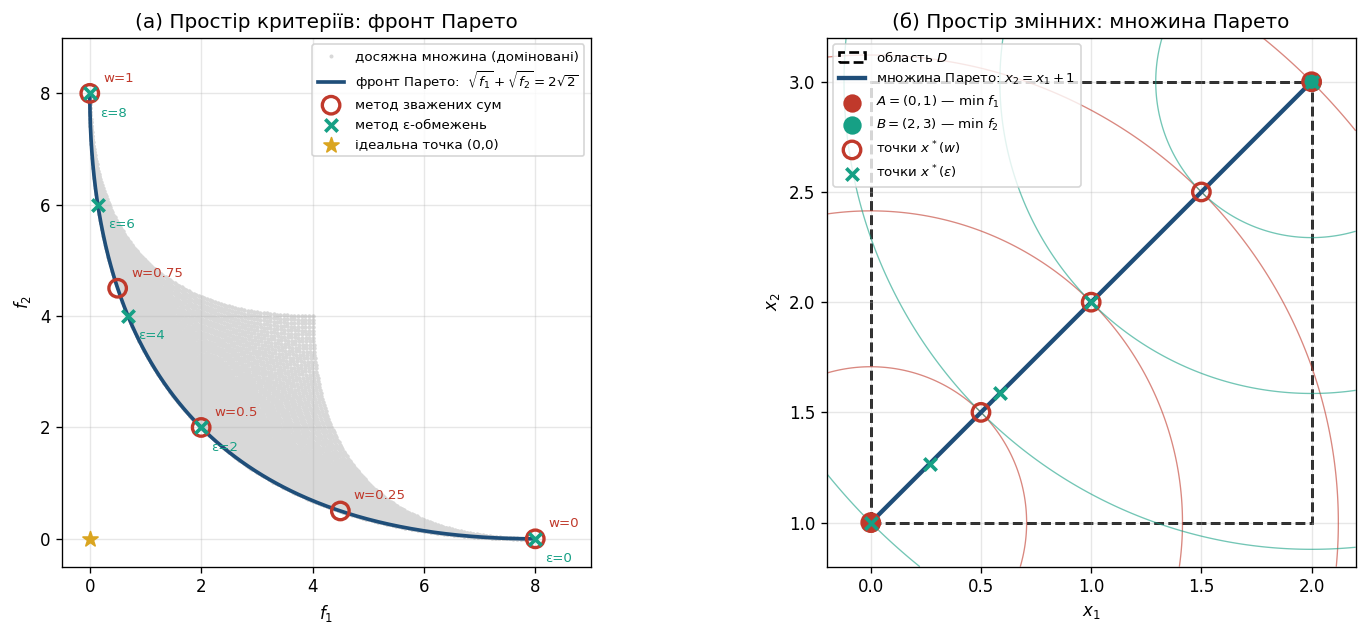

In [22]:
# Завдання 5: Графік фронту Парето
w_dense = np.linspace(0, 1, 400)
front_f1 = 8 * (1 - w_dense)**2
front_f2 = 8 * w_dense**2

ws_arr = np.array([[r[3], r[4]] for r in ws_rows])
eps_arr = np.array([[r[3], r[4]] for r in eps_rows])

fig, ax = plt.subplots(1, 2, figsize=(13, 5.4))

# --- (a) простір критеріїв ---
ax[0].scatter(FGRID[~mask, 0], FGRID[~mask, 1], s=2, c='#d8d8d8',
              label='досяжна множина (доміновані)', zorder=1)
ax[0].plot(front_f1, front_f2, '-', c='#1f4e79', lw=2.2,
           label=r'фронт Парето:  $\sqrt{f_1}+\sqrt{f_2}=2\sqrt{2}$', zorder=3)
ax[0].scatter(ws_arr[:, 0], ws_arr[:, 1], s=110, marker='o', facecolor='none',
              edgecolor='#c0392b', lw=2, label='метод зважених сум', zorder=5)
ax[0].scatter(eps_arr[:, 0], eps_arr[:, 1], s=55, marker='x', c='#16a085',
              lw=2.2, label='метод ε-обмежень', zorder=6)
ax[0].scatter([0], [0], s=90, marker='*', c='goldenrod',
              label='ідеальна точка (0,0)', zorder=7)
for (w, _, _, a, b) in ws_rows:
    ax[0].annotate(f'w={w:g}', (a, b), textcoords='offset points',
                   xytext=(8, 7), fontsize=8, color='#c0392b')
for (e, _, _, a, b) in eps_rows:
    ax[0].annotate(f'ε={e:g}', (a, b), textcoords='offset points',
                   xytext=(6, -14), fontsize=8, color='#16a085')
ax[0].set_xlabel('$f_1$'); ax[0].set_ylabel('$f_2$')
ax[0].set_title('(а) Простір критеріїв: фронт Парето')
ax[0].legend(fontsize=8, loc='upper right')
ax[0].set_xlim(-0.5, 9); ax[0].set_ylim(-0.5, 9)
ax[0].set_aspect('equal')

# --- (b) простір змінних ---
xx, yy = np.meshgrid(np.linspace(-0.2, 2.2, 300), np.linspace(0.8, 3.2, 300))
Z1 = xx**2 + (yy - 1)**2
Z2 = (xx - 2)**2 + (yy - 3)**2
ax[1].contour(xx, yy, Z1, levels=[0.5, 2, 4.5, 8], colors='#c0392b',
              linewidths=0.8, alpha=0.6)
ax[1].contour(xx, yy, Z2, levels=[0.5, 2, 4.5, 8], colors='#16a085',
              linewidths=0.8, alpha=0.6)
ax[1].add_patch(plt.Rectangle((0, 1), 2, 2, fill=False, ec='black',
                              lw=1.6, ls='--', label='область $D$'))
ax[1].plot([0, 2], [1, 3], '-', c='#1f4e79', lw=2.6,
           label='множина Парето: $x_2=x_1+1$')
ax[1].scatter(*A, s=100, c='#c0392b', zorder=5, label='$A=(0,1)$ — min $f_1$')
ax[1].scatter(*B, s=100, c='#16a085', zorder=5, label='$B=(2,3)$ — min $f_2$')
ws_x = np.array([[r[1], r[2]] for r in ws_rows])
eps_x = np.array([[r[1], r[2]] for r in eps_rows])
ax[1].scatter(ws_x[:, 0], ws_x[:, 1], s=110, marker='o', facecolor='none',
              edgecolor='#c0392b', lw=2, zorder=6, label='точки $x^*(w)$')
ax[1].scatter(eps_x[:, 0], eps_x[:, 1], s=55, marker='x', c='#16a085',
              lw=2.2, zorder=7, label='точки $x^*(ε)$')
ax[1].set_xlabel('$x_1$'); ax[1].set_ylabel('$x_2$')
ax[1].set_title('(б) Простір змінних: множина Парето')
ax[1].legend(fontsize=8, loc='upper left')
ax[1].set_aspect('equal')

plt.tight_layout()
plt.savefig('pareto_front_var4.png', dpi=150, bbox_inches='tight')
plt.show()

### 7. Порівняння методів та висновки


### 7.1. Порівняння ручних і чисельних результатів

Чисельні результати **повністю збігаються** з ручними викладками: максимальна похибка не перевищує $10^{-8}$ і визначається лише критерієм зупинки оптимізатора, а не методом. Зокрема:

* метод зважених сум: $x^\ast(w) = (2-2w,\ 3-2w)$, $f_1 = 8(1-w)^2$, $f_2 = 8w^2$;
* метод ε-обмежень: $x^\ast(\varepsilon) = (t,\ 1+t)$, $t = 2-\sqrt{\varepsilon/2}$, $f_1 = 2t^2$, $f_2 = \varepsilon$;
* обидва описують **один і той самий** фронт $\sqrt{f_1}+\sqrt{f_2} = 2\sqrt2$;
* незалежна перевірка прямим перебором із фільтром за домінуванням підтвердила, що множина Парето - відрізок $x_2 = x_1+1$, $x_1 \in [0,2]$, тобто відрізок $AB$.

Спільні точки двох методів: $w = 0 \leftrightarrow \varepsilon = 0$ (точка $(8,0)$), $w = 0.5 \leftrightarrow \varepsilon = 2$ (точка $(2,2)$), $w = 1 \leftrightarrow \varepsilon = 8$ (точка $(0,8)$).

### 7.2. Порівняння методів

| Критерій | Метод зважених сум | Метод ε-обмежень |
|---|---|---|
| Тип підзадачі | безумовна мінімізація (тут обмеження $D$ неактивні) | мінімізація з нелінійним обмеженням-нерівністю |
| Складність розв'язання | нижча: $\nabla J_w = 0$ - лінійна система | вища: потрібні ККТ або SLSQP |
| Неопуклі фронти | **не знаходить** точки в неопуклих ділянках | знаходить **усі** точки фронту |
| Керування результатом | непряме: $w$ задає лише нахил, не значення критеріїв | пряме: $\varepsilon$ задає саме значення $f_2$ |
| Потрібна підготовка | немає | потрібна таблиця виграшів для діапазону $\varepsilon$ |
| Ризик несумісності | відсутній | при $\varepsilon < f_{2,\min}$ задача несумісна |
| Рівномірність покриття | рівномірне $w$ ⇒ **нерівномірні** точки фронту | рівномірне $\varepsilon$ ⇒ рівномірне за $f_2$, нерівномірне за $f_1$ |
| Чутливість до масштабу критеріїв | висока (критерії треба нормувати) | низька |

### 7.3. Висновки

1. **Задача розв'язана обома методами, результати ідентичні.** Фронт Парето описується рівнянням $\sqrt{f_1}+\sqrt{f_2} = 2\sqrt2$, множина Парето — відрізок, що сполучає індивідуальні мінімуми $A=(0,1)$ і $B=(2,3)$: $x_2 = x_1+1$, $x_1\in[0,2]$.

2. **Фронт строго опуклий** ($d^2f_2/df_1^2 = \sqrt2 f_1^{-3/2} > 0$), тому метод зважених сум тут є повноцінним: він знаходить усі Парето-оптимальні точки. Якби фронт мав неопуклі ділянки, зважені суми їх принципово пропустили б, оскільки лінія рівня згортки - пряма, і вона дотикається лише до опуклої оболонки фронту. Метод ε-обмежень такої вади не має - саме тому його застосовують, коли про форму фронту нічого не відомо.

3. **Геометрична природа.** Обидва критерії — квадрати відстаней з однаковими гессіанами $2I$, тому розв'язок зважених сум є точною опуклою комбінацією індивідуальних мінімумів, $x^\ast(w) = wA + (1-w)B$, а множина Парето вироджується у прямолінійний відрізок. Це окремий "гарний" випадок; у загальному разі множина Парето - крива.

4. **Обмеження області $D$ не впливають на розв'язок.** Безумовні стаціонарні точки обох підзадач лежать у $D$ при всіх $w \in [0,1]$ і $\varepsilon \in [0,8]$, тому обмеження-нерівності залишаються неактивними. Фактично $D$ лише гарантує обмеженість досяжної множини.

5. **Параметризація != рівномірність, і "рівномірність" залежить від того, в чому її міряти.** Рівномірна сітка $\varepsilon$ за побудовою дає рівні кроки за координатою $f_2$ (0; 2; 4; 6; 8), але сильно нерівні за $f_1$ (8; 2; 0.686; 0.144; 0) - точки різко згущуються біля кінця $f_1 \to 0$. Рівномірна сітка $w$, навпаки, дає нерівні кроки за кожною окремою координатою ($f_2 = 0;\ 0.5;\ 2;\ 4.5;\ 8$), але **майже рівномірне покриття за довжиною дуги** фронту: кроки 3.54; 2.92; 2.92; 3.54 проти 6.32; 2.39; 2.07; 2.01 у ε-методу (коефіцієнти варіації 0.096 та 0.566 відповідно). Причина - симетрія фронту відносно бісектриси $f_1 = f_2$: параметр $w$ рухається вздовж фронту "рівномірніше", ніж $\varepsilon$, який майже третину шляху долає за один перший крок. Отже, для цієї задачі метод зважених сум дає візуально якісніше покриття фронту, і це не суперечить п. 2 - опуклість гарантує **досяжність** усіх точок, а не рівномірність їх розподілу. У загальному випадку рівномірного покриття не дає жодна з двох схем, і для цього застосовують спеціальні методи (NBI, NNC, адаптивне згущення сітки).

6. **Множник Лагранжа має змістовну інтерпретацію**: $\mu = (1-w)/w$ — це норма заміщення (trade-off ratio), тобто на скільки зросте $f_1$ при послабленні обмеження на $f_2$ на одиницю: $\mu = -df_1/d\varepsilon$. Перевірка: $f_1(\varepsilon) = (2\sqrt2-\sqrt\varepsilon)^2 \Rightarrow -df_1/d\varepsilon = \frac{2\sqrt2-\sqrt\varepsilon}{\sqrt\varepsilon} = \frac{2\sqrt2}{\sqrt\varepsilon}-1 = \mu$ - збігається з отриманим у п. 5.2.

7. **Практична рекомендація.** Для попереднього швидкого аналізу **зручніший метод зважених сум** (дешевші підзадачі, немає ризику несумісності). Для побудови якісного фронту в задачах із невідомою геометрією або жорсткими вимогами до окремих критеріїв слід використовувати метод ε-обмежень.